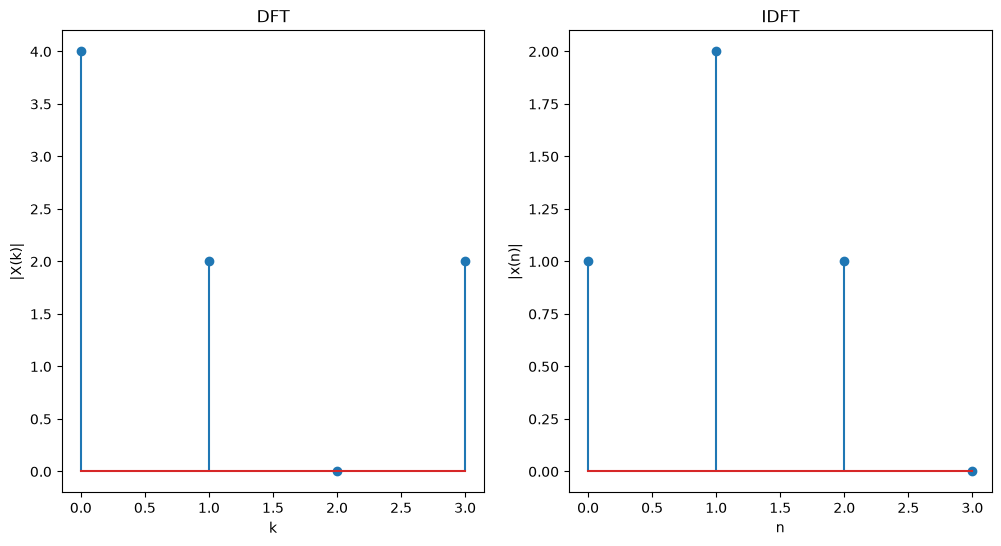

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# FUNÇÕES IMPLEMENTADAS PARA CÁLCULO DA DFT, IDFT E CONVOLUÇÃO CIRCULAR

def W_kn_N (k,n,N):
    return np.exp(-2j * np.pi * k * n / N)

def DFT(x_n, N):

    # Definição da matriz W_n
    W_n = np.zeros((N,N), dtype=complex)

    for k in range (0, N, 1):
        for n in range (0, N, 1):
            W_n[k][n] = W_kn_N(k,n,N)

    # Cálculo da DFT
    X_k = np.zeros(N, dtype=complex)
    for k in range(N):
        X_k[k] = np.sum(W_n[k] * x_n )

    return X_k

def IDFT(X_k, N):
    # Definição da matriz W_n
    W_n = np.zeros((N,N), dtype=complex)

    for k in range (0, N, 1):
        for n in range (0, N, 1):
            W_n[k][n] = W_kn_N(k,n,N)

    # Cálculo da IDFT
    x_n = np.zeros(N, dtype=complex)
    for n in range(N):
        x_n[n] = np.sum( np.conj(W_n[:,n]) * X_k ) / N

    return x_n

def convolucao_circular(x1_n, x2_n, N):
    y_n = np.zeros(N, dtype=complex)
    for n in range(N):
        for m in range(N):
            y_n[n] += x1_n[m] * x2_n[(n - m) % N]
    return y_n

N = 4 # Número de amostras para a DFT e IDFT (N >= len(x_n))

# Sinal x(n) de teste:
x_n_teste = np.array([1, 2, 1, 0], dtype=complex)

# Zero-padding do sinal x(n) para ter N amostras:
x_n = np.pad(x_n_teste, (0, N - len(x_n_teste)), 'constant')
X_k = DFT(x_n, N)
x_n_reconstruido = IDFT(X_k, N)

# Gráfico da DFT
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.stem(range(N), np.abs(X_k))
plt.xlabel('k')
plt.ylabel('|X(k)|')
plt.title('DFT')

# Gráfico da IDFT
plt.subplot(1, 2, 2)
plt.stem(range(N), np.abs(x_n_reconstruido))
plt.xlabel('n')
plt.ylabel('|x(n)|')
plt.title('IDFT')
plt.show()


In [2]:
# ---------- VERIFICAÇÃO DAS PROPRIEDADES DA DFT ----------- #

# SINAIS ALEATÓRIOS PARA TESTES:

x1_n = np.random.rand(N) + 1j * np.random.rand(N)
x2_n = np.random.rand(N) + 1j * np.random.rand(N)

# ----------- LINEARIDADE: DFT(a*x1(n) + b*x2(n)) = a*DFT(x1(n)) + b*DFT(x2(n))----------- #

a, b = 2, -3  # Coeficientes escalares
X1_k = DFT(x1_n, N)
X2_k = DFT(x2_n, N)
X3_k = DFT(a * x1_n + b * x2_n, N)
print("Propriedade da linearidade:")
print("Resultado da verificação =", np.allclose(X3_k, a * X1_k + b * X2_k))

# ------- DESLOCAMENTO NO TEMPO (circular): DFT(x(n-n0) mod N) = W^(-k*n0) * DFT(x(n)) ----------- #

n0 = 2  # Deslocamento no tempo
x1_n_t_deslocado = np.roll(x1_n, n0)
X1_k_t_deslocado = DFT(x1_n_t_deslocado, N)
print("Propriedade do deslocamento no tempo (circular):")
print("Resultado da verificação =", np.allclose(X1_k_t_deslocado, X1_k * W_kn_N(np.arange(N), n0, N)))

# ------- DESLOCAMENTO NA FREQUÊNCIA: DFT(x(n) * W^(-n*k0)) = X((k-k0) mod N) ----------- #

k0 = 3  # Deslocamento na frequência
x1_n_f_deslocado = x1_n * np.conj(W_kn_N(np.arange(N), k0, N))
X1_k_f_deslocado = DFT(x1_n_f_deslocado, N)
print("Propriedade do deslocamento na frequência:")
print("Resultado da verificação =", np.allclose(X1_k_f_deslocado, np.roll(X1_k, k0)))

# ------- REVERSÃO TEMPORAL: DFT(x(-n mod N)) = X(-k mod N) ----------- #

x1_n_reverso = np.roll(np.flip(x1_n), 1)
X1_k_reverso = DFT(x1_n_reverso, N)
print("Propriedade da reversão temporal:")
print("Resultado da verificação =", np.allclose(X1_k_reverso, np.roll(np.flip(X1_k), 1)))

# ------- CONJUGAÇÃO COMPLEXA: DFT(conj(x(n))) = conj(X(-k mod N)) ----------- #

x1_n_conj = np.conj(x1_n)
X1_k_conj = DFT(x1_n_conj, N)
print("Propriedade da conjugação complexa:")
print("Resultado da verificação =", np.allclose(X1_k_conj, np.conj(np.roll(np.flip(X1_k), 1))))

# ------- CONVOLUÇÃO CIRCULAR: DFT(x1(n) @ x2(n)) = X1(n) * X2(n) ----------- #

y_n = convolucao_circular(x1_n, x2_n, N)
Y_k = DFT(y_n, N)
print("Propriedade da convolução circular:")
print("Resultado da verificação =", np.allclose(Y_k, X1_k * X2_k))

# ------- MULTIPLICAÇÃO PONTO A PONTO: DFT(x1(n) * x2(n)) = (X1(n) @ X2(n))/N ----------- #

y_n = x1_n * x2_n
Y_k = DFT(y_n, N)
print("Propriedade da multiplicação ponto a ponto:")
print("Resultado da verificação =", np.allclose(Y_k, convolucao_circular(X1_k, X2_k, N) / N))

# ------- PARSEVAL: sum(|x(n)|^2) = (1/N) * sum(|X(k)|^2) ----------- #

soma_x = np.sum(np.abs(x1_n)**2)
soma_X = (1/N) * np.sum(np.abs(X1_k)**2)
print("Propriedade de Parseval:")
print("Resultado da verificação =", np.allclose(soma_x, soma_X))

# ------- PERIODICIDADE: X(k) = X(k + N) ----------- #

print("Propriedade da periodicidade:")
print("Resultado da verificação =", np.allclose(X1_k, np.roll(X1_k, N)))

# ------- SIMETRIA PARA SINAIS REAIS: conj(X(k)) = X(N - k) ----------- #

x1_n_real = np.real(x1_n)  # Tornando o sinal real
X1_k_real = DFT(x1_n_real, N)
print("Propriedade da simetria para sinais reais:")
print("Resultado da verificação =", np.allclose(np.conj(X1_k_real), np.roll(np.flip(X1_k_real), 1)))

Propriedade da linearidade:
Resultado da verificação = True
Propriedade do deslocamento no tempo (circular):
Resultado da verificação = True
Propriedade do deslocamento na frequência:
Resultado da verificação = True
Propriedade da reversão temporal:
Resultado da verificação = True
Propriedade da conjugação complexa:
Resultado da verificação = True
Propriedade da convolução circular:
Resultado da verificação = True
Propriedade da multiplicação ponto a ponto:
Resultado da verificação = True
Propriedade de Parseval:
Resultado da verificação = True
Propriedade da periodicidade:
Resultado da verificação = True
Propriedade da simetria para sinais reais:
Resultado da verificação = True
